# 5. Unsupervised analysis: PCA and k-means

Segment students using the numeric academic and macroeconomic variables, without the outcome, and then check how the segments relate to it.

In [1]:
import sys
sys.path.append("../src")
from pathlib import Path

FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from preprocessing import load_data, validate_data, add_features, fit_age_cap, apply_age_cap

df = load_data("../data/students.csv")
outcome = df["target"].copy()  # kept aside, only used to interpret the clusters
df = validate_data(df)
df = add_features(df)
df = apply_age_cap(df, fit_age_cap(df))  # no test set here, so the cap uses all rows

numeric_vars = ["age_at_enrollment", "previous_qualification_grade", "admission_grade",
                "units_1st_enrolled", "units_1st_evaluations",
                "units_1st_approved", "grade_1st", "units_1st_no_evaluation",
                "units_2nd_enrolled", "units_2nd_evaluations",
                "units_2nd_approved", "grade_2nd", "units_2nd_no_evaluation",
                "unemployment_rate", "inflation_rate", "gdp",
                "pass_ratio_1st", "pass_ratio_2nd", "total_units_enrolled"]

X_scaled = StandardScaler().fit_transform(df[numeric_vars])

[validation] no issues found


## PCA

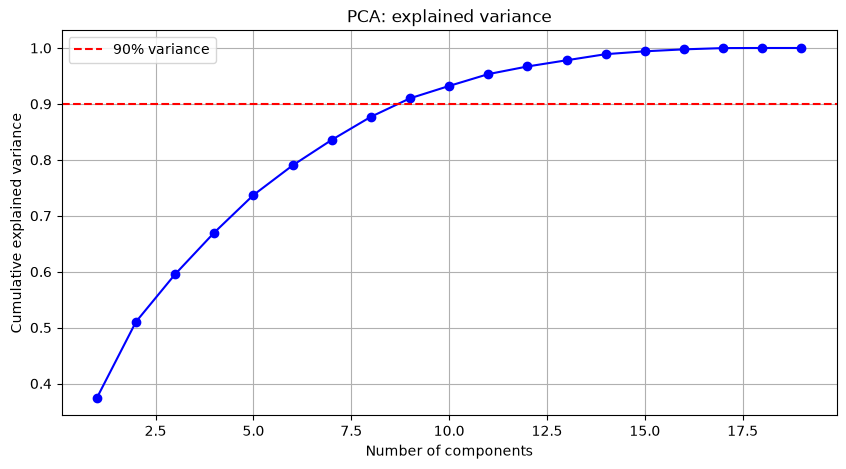

components for 90% of the variance: 9


In [2]:
pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, "bo-")
plt.axhline(y=0.90, color="r", linestyle="--", label="90% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: explained variance")
plt.legend()
plt.grid(True)
plt.show()

print(f"components for 90% of the variance: {np.argmax(cum_var >= 0.90) + 1}")

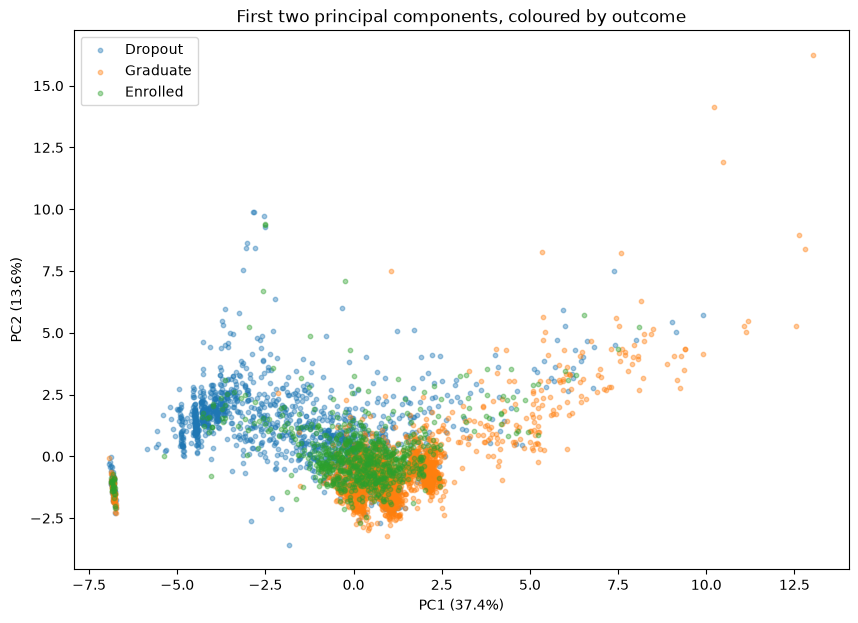

In [3]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
for label in ["Dropout", "Graduate", "Enrolled"]:
    mask = outcome == label
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=label, alpha=0.4, s=10)
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]:.1%})")
plt.title("First two principal components, coloured by outcome")
plt.legend()
plt.show()

## Choosing k

Inertia (elbow) and silhouette score for k = 2..8.

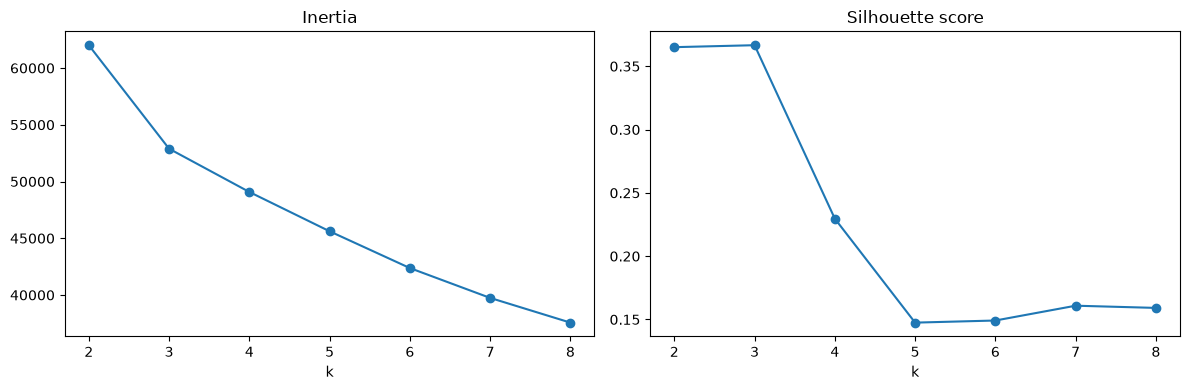

 k  silhouette
 2       0.365
 3       0.367
 4       0.230
 5       0.148
 6       0.149
 7       0.161
 8       0.159


In [4]:
ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertia.append(km_k.inertia_)
    silhouette.append(silhouette_score(X_scaled, km_k.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(list(ks), inertia, "o-")
ax1.set_xlabel("k")
ax1.set_title("Inertia")
ax2.plot(list(ks), silhouette, "o-")
ax2.set_xlabel("k")
ax2.set_title("Silhouette score")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"k": list(ks), "silhouette": np.round(silhouette, 3)}).to_string(index=False))

## k-means with k = 3

k = 3 has the highest silhouette score (0.367, against 0.365 for k = 2), and it also matches the number of outcome classes, which makes the segments easier to compare with the target.

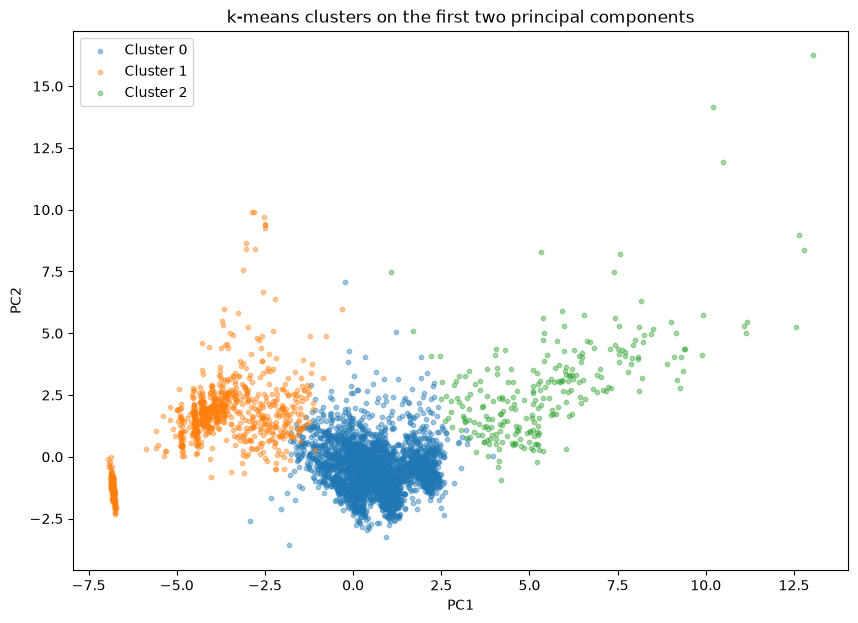

col_0        0    1    2   All
target                        
Dropout    622  745   54  1421
Enrolled   675   85   34   794
Graduate  1965   76  168  2209
All       3262  906  256  4424
col_0         0      1      2
target                       
Dropout   0.191  0.822  0.211
Enrolled  0.207  0.094  0.133
Graduate  0.602  0.084  0.656


In [5]:
k = 3
km = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = km.fit_predict(X_scaled)

plt.figure(figsize=(10, 7))
for c in range(k):
    mask = clusters == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], label=f"Cluster {c}", alpha=0.4, s=10)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("k-means clusters on the first two principal components")
plt.legend()
plt.savefig(FIGURES / "kmeans_pca.png", dpi=120, bbox_inches="tight")
plt.show()

print(pd.crosstab(outcome, clusters, margins=True))
print(pd.crosstab(outcome, clusters, normalize="columns").round(3))

## Cluster profiles

Mean of each variable per cluster.

In [6]:
profile = df[numeric_vars].assign(cluster=clusters).groupby("cluster").mean().T
print(profile.round(2).to_string())

cluster                            0       1       2
age_at_enrollment              22.10   25.79   28.31
previous_qualification_grade  132.71  132.47  131.94
admission_grade               126.97  126.33  129.44
units_1st_enrolled              6.20    4.48   13.52
units_1st_evaluations           8.53    5.00   17.08
units_1st_approved              5.32    0.46   11.88
grade_1st                      12.76    2.43   12.67
units_1st_no_evaluation         0.08    0.24    0.45
units_2nd_enrolled              6.26    4.54   11.86
units_2nd_evaluations           8.61    4.14   15.04
units_2nd_approved              5.18    0.10   10.31
grade_2nd                      12.68    0.70   12.68
units_2nd_no_evaluation         0.10    0.28    0.31
unemployment_rate              11.57   11.60   11.41
inflation_rate                  1.19    1.32    1.39
gdp                             0.07   -0.24   -0.07
pass_ratio_1st                  0.86    0.08    0.87
pass_ratio_2nd                  0.82    0.02  